# Hangi paketleme yöntemleri farklı?

A, B ve C paketleme yöntemleri için 24, 30 ve 36 bağımsız uygun paket ölçülüyor. Genel test fark olduğunu söyleyebilir; yönetici hangi çiftte ne kadar fark olduğunu bilmek istiyor. İkinci senaryoda yöntemlerin oynaklığı eşit değil. Üç bağımsız t testini düzeltmesiz yapmak yerine karşılaştırma ailesi önceden tanımlanmalı.

**Karar:** Hangi yöntem çiftleri arasında desteklenen süre farkı var; ortak varyans varsayımı uygun mu?

**Birim:** Bağımsız birim: uygun paket. Hedef: her yöntem çiftinin ortalama süre farkı.

**Yöntem:** Ortak koşullar ve grup dağılımlarını incele. Ortak varyans tasarımında klasik ANOVA + Tukey; eşit olmayan varyansta Welch + Games–Howell gerekçesini kur. Sadece genel p ile bütün çiftlerin farklı olduğunu söyleme.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: Benzer varyans

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                Ölçü Değer
Klasik genel ANOVA p   0.0
       Welch genel p   0.0
      Bağımsız paket    90
   Varyans senaryosu  Eşit

Grup hacmi, merkezi ve yayılımı
method  count      mean      std
     A     24 19.929993 1.637829
     B     30 18.058993 1.556322
     C     36 17.086091 1.582036

Games–Howell: A−B yönü
pair  difference        df   p_adjusted    lower    upper
 A−B    1.871000 48.258469 2.697725e-04 0.810050 2.931949
 A−C    2.843902 48.245243 6.655646e-08 1.814311 3.873493
 B−C    0.972903 62.220203 3.851350e-02 0.042171 1.903635

Tukey: tablodaki meandiff = group2−group1
group1 group2  meandiff  p-adj   lower   upper  reject
     A      B   -1.8710 0.0001 -2.9083 -0.8337    True
     A      C   -2.8439 0.0000 -3.8421 -1.8457    True
     B      C   -0.9729 0.0398 -1.9093 -0.0365    True

Karar: Eşit varyanslı öğretim senaryosunda klasik ANOVA ve Tukey tutarlı bir aile oluşturur. Eşit olmayan senaryoda Welch + Games–Howell seç; her çifti düzeltilmemiş t testleriyle 

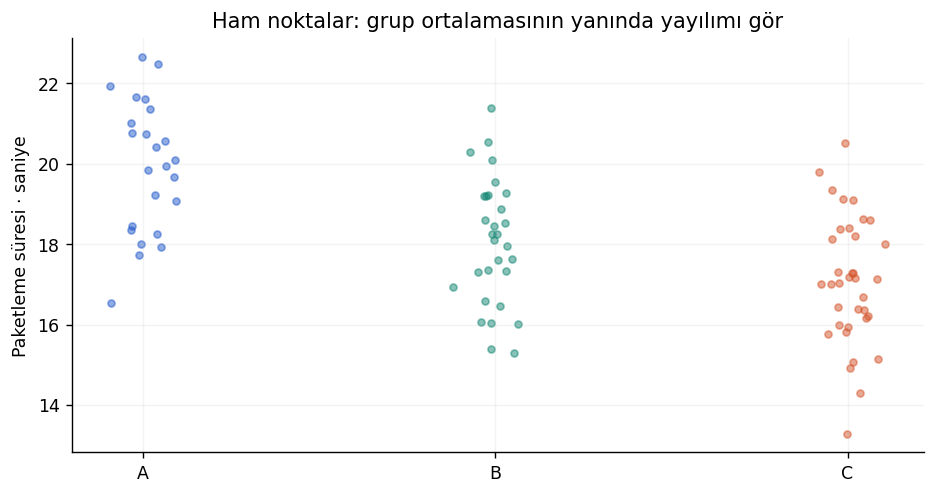

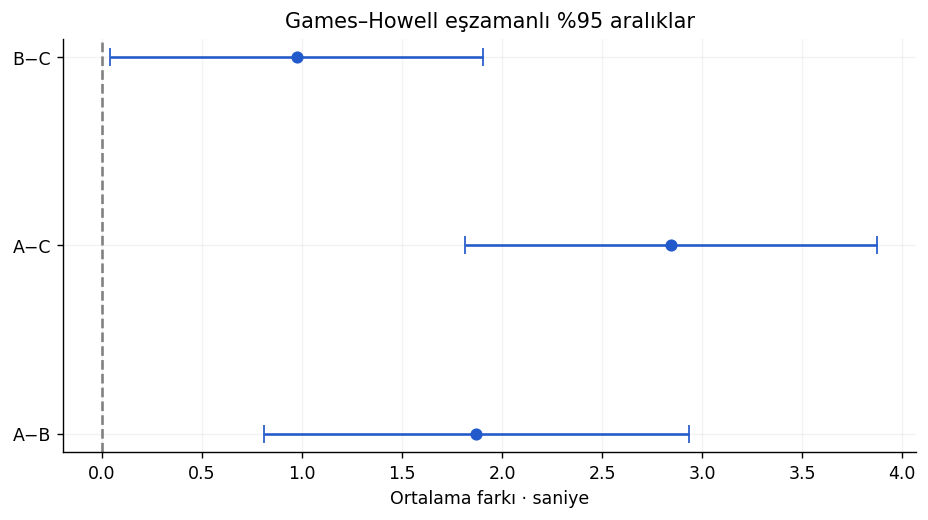

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def posthoc(scenario='default'):
 rng=np.random.default_rng(260803);names=['A','B','C'];ns=[24,30,36];means=[20,18.5,17.5];scales=[1.5]*3 if scenario=='default' else [1.,2.5,4.];groups=[rng.normal(mu,sd,n) for mu,sd,n in zip(means,scales,ns)];raw=pd.DataFrame([(name,float(v))for name,g in zip(names,groups)for v in g],columns=['method','seconds']);welch=anova_oneway(groups,use_var='unequal');classic=stats.f_oneway(*groups);tukey=pairwise_tukeyhsd(raw.seconds,raw.method,alpha=.05);gh=[]
 for i in range(3):
  for j in range(i+1,3):
   gi,gj=groups[i],groups[j];vi,vj=np.var(gi,ddof=1)/len(gi),np.var(gj,ddof=1)/len(gj);se=np.sqrt(vi+vj);df=(vi+vj)**2/(vi**2/(len(gi)-1)+vj**2/(len(gj)-1));difference=gi.mean()-gj.mean();q=np.sqrt(2)*abs(difference)/se;critical=stats.studentized_range.ppf(.95,3,df)/np.sqrt(2);p=stats.studentized_range.sf(q,3,df);gh.append([names[i]+'−'+names[j],difference,df,p,difference-critical*se,difference+critical*se])
 ghdf=pd.DataFrame(gh,columns=['pair','difference','df','p_adjusted','lower','upper']);summary=raw.groupby('method').seconds.agg(['count','mean','std']).reset_index();fig,ax=plt.subplots();
 for i,g in enumerate(groups):ax.scatter(np.full(len(g),i)+rng.normal(0,.04,len(g)),g,alpha=.5,s=16,color=['#235ACB','#148774','#D5542B'][i])
 ax.set(xticks=range(3),xticklabels=names,ylabel='Paketleme süresi · saniye',title='Ham noktalar: grup ortalamasının yanında yayılımı gör')
 fig2,ax2=plt.subplots();ax2.axvline(0,color='gray',ls='--');ax2.errorbar(ghdf.difference,range(3),xerr=np.vstack([ghdf.difference-ghdf.lower,ghdf.upper-ghdf.difference]),fmt='o',capsize=5,color='#235ACB');ax2.set(yticks=range(3),yticklabels=ghdf.pair,xlabel='Ortalama farkı · saniye',title='Games–Howell eşzamanlı %95 aralıklar')
 tdf=pd.DataFrame(tukey._results_table.data[1:],columns=tukey._results_table.data[0]);assert np.all((ghdf.p_adjusted>=0)&(ghdf.p_adjusted<=1));assert np.all(ghdf.lower<=ghdf.upper)
 decision='Eşit varyanslı öğretim senaryosunda klasik ANOVA ve Tukey tutarlı bir aile oluşturur. Eşit olmayan senaryoda Welch + Games–Howell seç; her çifti düzeltilmemiş t testleriyle tarama.'
 return dict(metrics={'Klasik genel ANOVA p':classic.pvalue,'Welch genel p':float(welch.pvalue),'Bağımsız paket':len(raw),'Varyans senaryosu':'Eşit' if scenario=='default' else 'Eşit değil'},tables=[tbl(summary,'Grup hacmi, merkezi ve yayılımı'),tbl(ghdf,'Games–Howell: A−B yönü'),tbl(tdf,'Tukey: tablodaki meandiff = group2−group1')],figures=[('Her nokta bağımsız bir paket ölçümüdür; renk yöntemdir.',fig),('Sıfırı dışlayan eşzamanlı aralık ilgili çiftin farkını destekler; yönleri tablodaki etikete göre oku.',fig2)],frames={'paket_olcumleri':raw},steps=['Üç bağımsız yöntem grubunda n, ortalama, varyans ve ham dağılımı kontrol et.','Genel H0 bütün ortalamalar eşit. Klasik ANOVA ortak varyans, Welch ayrı varyans hedefiyle kurulur.','Tukey ortak hata varyansına; Games–Howell çiftin ayrı varyansına ve Welch df’sine dayanır. Games–Howell q=√2×|fark|/SE; aile büyüklüğü k=3.'],decision=decision,diagnostics={'classic_p':classic.pvalue,'welch_p':float(welch.pvalue),'gh':ghdf.to_dict('records'),'ns':ns,'stds':[np.std(g,ddof=1)for g in groups]},limit='Sentetik bağımsız normal paket ölçümleri; yöntemler uygun paketlere rastgele atanmış varsayılır. Gerçek çalışmada operatör/vardiya ve sıra etkisi blok gerektirebilir. Varyans ailesi yalnız Levene p’sine göre otomatik seçilmez. İstatistiksel fark işte en iyi yöntem demek değildir.')

result=posthoc('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: Farklı varyans

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                Ölçü      Değer
Klasik genel ANOVA p   0.000205
       Welch genel p   0.000001
      Bağımsız paket         90
   Varyans senaryosu Eşit değil

Grup hacmi, merkezi ve yayılımı
method  count      mean      std
     A     24 19.953329 1.091886
     B     30 17.764989 2.593870
     C     36 16.396242 4.218762

Games–Howell: A−B yönü
pair  difference        df  p_adjusted     lower    upper
 A−B    2.188340 40.748900    0.000432  0.915321 3.461358
 A−C    3.557087 41.745542    0.000056  1.764679 5.349494
 B−C    1.368747 59.243253    0.247517 -0.669209 3.406703

Tukey: tablodaki meandiff = group2−group1
group1 group2  meandiff  p-adj   lower   upper  reject
     A      B   -2.1883 0.0321 -4.2240 -0.1526    True
     A      C   -3.5571 0.0001 -5.5159 -1.5982    True
     B      C   -1.3687 0.1836 -3.2063  0.4688   False

Karar: Eşit varyanslı öğretim senaryosunda klasik ANOVA ve Tukey tutarlı bir aile oluşturur. Eşit olmayan senaryoda Welch + Games–Howell seç; her çifti düz

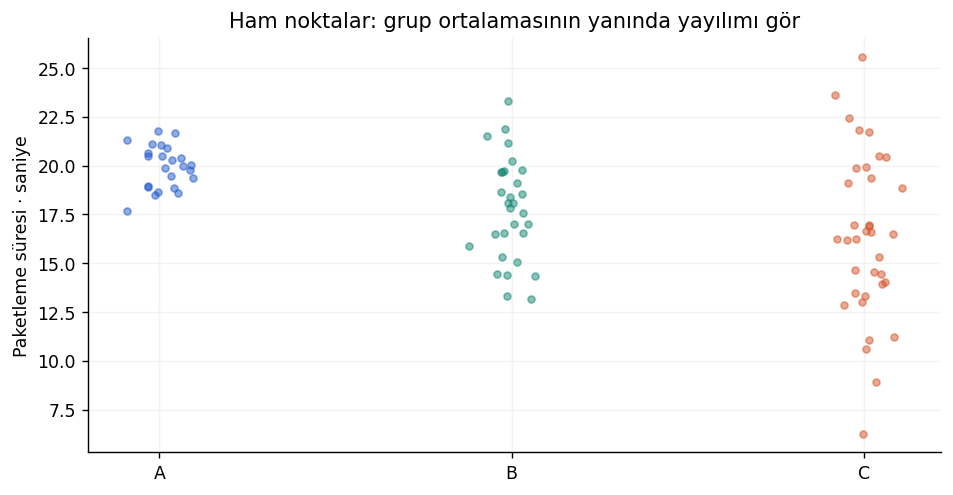

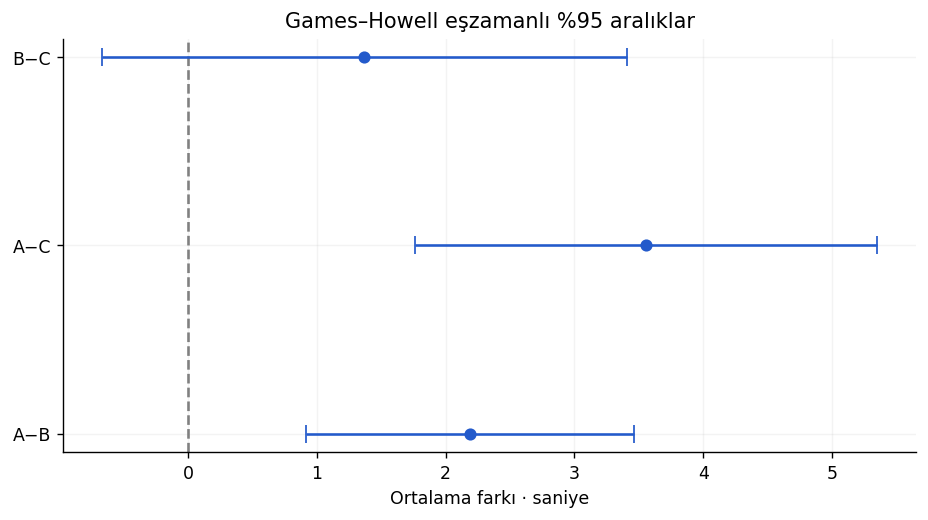

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def posthoc(scenario='default'):
 rng=np.random.default_rng(260803);names=['A','B','C'];ns=[24,30,36];means=[20,18.5,17.5];scales=[1.5]*3 if scenario=='default' else [1.,2.5,4.];groups=[rng.normal(mu,sd,n) for mu,sd,n in zip(means,scales,ns)];raw=pd.DataFrame([(name,float(v))for name,g in zip(names,groups)for v in g],columns=['method','seconds']);welch=anova_oneway(groups,use_var='unequal');classic=stats.f_oneway(*groups);tukey=pairwise_tukeyhsd(raw.seconds,raw.method,alpha=.05);gh=[]
 for i in range(3):
  for j in range(i+1,3):
   gi,gj=groups[i],groups[j];vi,vj=np.var(gi,ddof=1)/len(gi),np.var(gj,ddof=1)/len(gj);se=np.sqrt(vi+vj);df=(vi+vj)**2/(vi**2/(len(gi)-1)+vj**2/(len(gj)-1));difference=gi.mean()-gj.mean();q=np.sqrt(2)*abs(difference)/se;critical=stats.studentized_range.ppf(.95,3,df)/np.sqrt(2);p=stats.studentized_range.sf(q,3,df);gh.append([names[i]+'−'+names[j],difference,df,p,difference-critical*se,difference+critical*se])
 ghdf=pd.DataFrame(gh,columns=['pair','difference','df','p_adjusted','lower','upper']);summary=raw.groupby('method').seconds.agg(['count','mean','std']).reset_index();fig,ax=plt.subplots();
 for i,g in enumerate(groups):ax.scatter(np.full(len(g),i)+rng.normal(0,.04,len(g)),g,alpha=.5,s=16,color=['#235ACB','#148774','#D5542B'][i])
 ax.set(xticks=range(3),xticklabels=names,ylabel='Paketleme süresi · saniye',title='Ham noktalar: grup ortalamasının yanında yayılımı gör')
 fig2,ax2=plt.subplots();ax2.axvline(0,color='gray',ls='--');ax2.errorbar(ghdf.difference,range(3),xerr=np.vstack([ghdf.difference-ghdf.lower,ghdf.upper-ghdf.difference]),fmt='o',capsize=5,color='#235ACB');ax2.set(yticks=range(3),yticklabels=ghdf.pair,xlabel='Ortalama farkı · saniye',title='Games–Howell eşzamanlı %95 aralıklar')
 tdf=pd.DataFrame(tukey._results_table.data[1:],columns=tukey._results_table.data[0]);assert np.all((ghdf.p_adjusted>=0)&(ghdf.p_adjusted<=1));assert np.all(ghdf.lower<=ghdf.upper)
 decision='Eşit varyanslı öğretim senaryosunda klasik ANOVA ve Tukey tutarlı bir aile oluşturur. Eşit olmayan senaryoda Welch + Games–Howell seç; her çifti düzeltilmemiş t testleriyle tarama.'
 return dict(metrics={'Klasik genel ANOVA p':classic.pvalue,'Welch genel p':float(welch.pvalue),'Bağımsız paket':len(raw),'Varyans senaryosu':'Eşit' if scenario=='default' else 'Eşit değil'},tables=[tbl(summary,'Grup hacmi, merkezi ve yayılımı'),tbl(ghdf,'Games–Howell: A−B yönü'),tbl(tdf,'Tukey: tablodaki meandiff = group2−group1')],figures=[('Her nokta bağımsız bir paket ölçümüdür; renk yöntemdir.',fig),('Sıfırı dışlayan eşzamanlı aralık ilgili çiftin farkını destekler; yönleri tablodaki etikete göre oku.',fig2)],frames={'paket_olcumleri':raw},steps=['Üç bağımsız yöntem grubunda n, ortalama, varyans ve ham dağılımı kontrol et.','Genel H0 bütün ortalamalar eşit. Klasik ANOVA ortak varyans, Welch ayrı varyans hedefiyle kurulur.','Tukey ortak hata varyansına; Games–Howell çiftin ayrı varyansına ve Welch df’sine dayanır. Games–Howell q=√2×|fark|/SE; aile büyüklüğü k=3.'],decision=decision,diagnostics={'classic_p':classic.pvalue,'welch_p':float(welch.pvalue),'gh':ghdf.to_dict('records'),'ns':ns,'stds':[np.std(g,ddof=1)for g in groups]},limit='Sentetik bağımsız normal paket ölçümleri; yöntemler uygun paketlere rastgele atanmış varsayılır. Gerçek çalışmada operatör/vardiya ve sıra etkisi blok gerektirebilir. Varyans ailesi yalnız Levene p’sine göre otomatik seçilmez. İstatistiksel fark işte en iyi yöntem demek değildir.')

result=posthoc('heterogeneous')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Farklı varyans senaryosunda ham noktaları ve eşzamanlı aralıkları oku. Aynı p eşiğiyle, varsayımı uygun olmayan bir yöntemin sonucunu otomatik seçme.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
